# Cafe Cup Picking with a Four-View CNN and YOLO26 Pose

The request-conditioned CNN proposes grasp points for all four cameras. A reachable SW grasp with adequate observability takes priority. Other cameras and YOLO pose detections help select a fallback when SW is unreliable.


In [51]:
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    drive.mount("/content/drive")
    # Change this path if your code folder is elsewhere in Drive.
    PROJECT_DIR = Path("/content/drive/MyDrive/student/cafe_project")
    DATA_DIR = Path("/content/dataset")       # Local disk on the Colab server.
    SAVE_PATH = PROJECT_DIR / "runs"          # Keep results and weights in Drive.
else:
    PROJECT_DIR = Path('.').expanduser().resolve()
    DATA_DIR = Path("./dataset").expanduser().resolve()
    SAVE_PATH = Path("./runs").expanduser().resolve()

DATASET_ZIP = PROJECT_DIR / "dataset.zip"  # Set None if already extracted manually.
if not (PROJECT_DIR / "requirements.txt").is_file():
    raise FileNotFoundError("Set PROJECT_DIR to the code folder containing requirements.txt.")
print("Code:", PROJECT_DIR)
print("Dataset:", DATA_DIR)
print("Results:", SAVE_PATH)


Code: C:\Users\lucas\Downloads\cafe_project-20261118T022300Z-1-001\cafe_project
Dataset: C:\Users\lucas\Downloads\cafe_project-20261118T022300Z-1-001\cafe_project\dataset
Results: C:\Users\lucas\Downloads\cafe_project-20261118T022300Z-1-001\cafe_project\runs


## Install Packages

The notebook uses Ultralytics 8.4.210 for YOLO26.

For submission, include `ultralytics==8.4.210` in the submitted `requirements.txt`.

In [52]:
requirements_path = str(PROJECT_DIR / "requirements.txt")
%pip install -r "{requirements_path}" "ultralytics==8.4.210"

Note: you may need to restart the kernel to use updated packages.


## 1. Prepare the Data
Extract DATASET_ZIP into DATA_DIR and save results under SAVE_PATH, as configured in section 0.
For manually extracted data, set DATASET_ZIP=None and select its DATA_DIR in section 0.
Completed extraction is reused. Prepare the data again after starting a new Colab runtime.


In [53]:
from datetime import datetime
import os
import sys

SAVE_PATH.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
os.environ.setdefault("MPLCONFIGDIR", str(SAVE_PATH / "matplotlib_cache"))


'C:\\Users\\lucas\\Downloads\\cafe_project-20261118T022300Z-1-001\\cafe_project\\runs\\matplotlib_cache'

In [54]:
from common.data_setup import prepare_dataset

# Reuse the dataset if this ZIP has already been extracted.
DATA_DIR = prepare_dataset(DATASET_ZIP, DATA_DIR)


Dataset already extracted: C:\Users\lucas\Downloads\cafe_project-20261118T022300Z-1-001\cafe_project\dataset


In [55]:
import os
from pathlib import Path

import numpy as np

VIEWS = ("sw", "se", "ne", "nw")
COLORS = ("red", "blue", "green", "yellow", "black", "white")
PATTERNS = ("plain", "flower", "bird", "leaf", "stripes")
CUP_CLASSES = [f"{color}_{pattern}" for color in COLORS for pattern in PATTERNS]
IMAGE_SIZE = 384
WORKSPACE_LOW = np.array([0.05, -0.65, 0.015])
WORKSPACE_HIGH = np.array([0.85, 0.50, 0.85])

In [56]:
import torch

MODEL_NAME = "improved"
MAX_LEVEL = 3
CHECKPOINT_PATH = PROJECT_DIR / "weights" / "improved.pt"
RUN_DIR = SAVE_PATH / ("improved_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


## 2. Export YOLO Pose Labels

Each scene-view image gets one label file that combines its visible cup annotations. The export preserves the supplied TRAIN and VAL scene assignments and uses all three levels for detector development. `MAX_LEVEL` controls the later picking evaluation.

Each cup has a color-pattern class, a box, and one keypoint. When the official point is unavailable, the export uses the visible handle pixel nearest the handle mask centroid. A cup with no visible handle or official point retains its box and has an unlabeled keypoint. These exported points are used by YOLO during training and its internal validation. The course evaluator still uses the original dataset annotations.

In [57]:
from collections import defaultdict
from shutil import copyfile

from PIL import Image
import yaml

from common.catalog import read_json, samples, scene_folder


def export_pose_dataset(data_root, output):
    root = Path(output).resolve()
    class_ids = {name: index for index, name in enumerate(CUP_CLASSES)}

    for split in ("train", "val"):
        scenes = defaultdict(list)
        for row in samples(3, split, data_root):
            scenes[row["scene_id"]].append(row)

        image_dir = root / "images" / split
        label_dir = root / "labels" / split
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)

        for scene_id, rows in scenes.items():
            folder = scene_folder(rows[0], data_root)
            annotations = []
            for row in rows:
                request = row["request"]
                class_id = class_ids[f"{request['color']}_{request['pattern']}"]
                label_dir_for_request = folder / "label" / row["request_id"]
                points = read_json(label_dir_for_request / "points.json")
                annotations.append((class_id, label_dir_for_request, points))

            for view in VIEWS:
                image = folder / "rgb" / f"{view}.png"
                with Image.open(image) as rgb:
                    width, height = rgb.size
                labels = []
                for class_id, request_dir, points in annotations:
                    label = points[view]
                    box = label["visible_bbox_xyxy_exclusive"]
                    if box is None:
                        continue
                    x0, y0, x1, y1 = box
                    xywh = ((x0 + x1) / (2 * width), (y0 + y1) / (2 * height),
                            (x1 - x0) / width, (y1 - y0) / height)

                    point = label["reference_uv"] if label["coordinate_loss_valid"] else None
                    if point is None:
                        with Image.open(request_dir / label["target_parts"]) as mask:
                            v, u = np.nonzero(np.asarray(mask) == 2)
                        if u.size:
                            nearest = np.argmin((u - u.mean()) ** 2 + (v - v.mean()) ** 2)
                            point = (u[nearest], v[nearest])
                    keypoint = (0.0, 0.0, 0) if point is None else (point[0] / width, point[1] / height, 2)
                    labels.append(" ".join(map(str, (class_id, *xywh, *keypoint))))

                name = f"{scene_id}_{view}"
                copyfile(image, image_dir / f"{name}.png")
                (label_dir / f"{name}.txt").write_text("\n".join(labels), encoding="utf-8")

    data_yaml = root / "cups_pose.yaml"
    data_yaml.write_text(yaml.safe_dump({
        "path": root.as_posix(),
        "train": "images/train",
        "val": "images/val",
        "names": CUP_CLASSES,
        "kpt_shape": [1, 3],
        "flip_idx": [0],
    }, sort_keys=False), encoding="utf-8")
    return data_yaml

## 3–4. Train YOLO26n Pose

Set `RUN_TRAINING=True` to export the dataset and fine-tune YOLO26n Pose. The first training run can download the initial Ultralytics weights. The best trained checkpoint is saved to `weights/improved.pt`, and training results remain in the run directory.

YOLO uses CUDA when available and otherwise uses the CPU.

For a quick check, use `EPOCHS=1`. For later notebook runs, use `RUN_TRAINING=False` to load the trained checkpoint.

In [58]:
RUN_TRAINING = False
EPOCHS = 30
BATCH_SIZE = 8

if RUN_TRAINING:
    from ultralytics import YOLO

    data_yaml = export_pose_dataset(DATA_DIR, RUN_DIR / "pose_data")
    model = YOLO(str(RUN_DIR / "yolo26n-pose.pt"))
    model.train(data=str(data_yaml), project=str(RUN_DIR), name="train",
                imgsz=IMAGE_SIZE, epochs=EPOCHS, batch=BATCH_SIZE, device=DEVICE,
                workers=0, seed=17, amp=DEVICE.startswith("cuda"))

    CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
    staged_checkpoint = CHECKPOINT_PATH.with_name(f".{CHECKPOINT_PATH.name}.{RUN_DIR.name}.tmp")
    copyfile(model.trainer.best, staged_checkpoint)
    staged_checkpoint.replace(CHECKPOINT_PATH)
    print("Checkpoint:", CHECKPOINT_PATH)

## 5. Coordinate Transforms

Convert the selected pixel into a world point using that camera's valid depth, intrinsics, and camera-to-world transform.

In [59]:
def pixel_to_camera(uv, depth_m, K):
    """Convert pixels and camera-z depth to camera coordinates.

    Input: uv (..., 2), depth_m (...), K (3, 3). Output: (..., 3).
    Support both a single point [u, v] and a batch of points [N, 2].
    Formula: camera_point = depth * inverse(K) * [u, v, 1].
    """
    pixel_uv = np.asarray(uv, dtype=float)
    depth_values = np.asarray(depth_m, dtype=float)
    intrinsic_matrix = np.asarray(K, dtype=float)

    if pixel_uv.shape[-1:] != (2,):
        raise ValueError("uv must end with two coordinates: [u, v]")
    if depth_values.shape != pixel_uv.shape[:-1]:
        raise ValueError("Each pixel must have one depth value")
    if intrinsic_matrix.shape != (3, 3):
        raise ValueError("K must be a 3-by-3 matrix")
    if not np.isfinite(pixel_uv).all():
        raise ValueError("Pixel coordinates must be finite")
    if not np.isfinite(depth_values).all() or (depth_values <= 0).any():
        raise ValueError("Depth must be finite and positive")

    # Append 1 to [u, v] to obtain homogeneous pixel coordinates.
    ones_shape = pixel_uv.shape[:-1] + (1,)
    ones = np.ones(ones_shape)
    homogeneous_pixels = np.concatenate([pixel_uv, ones], axis=-1)

    # Points are row vectors, so multiply by the transposed rotation on the right.
    inverse_intrinsics = np.linalg.inv(intrinsic_matrix)
    camera_rays = homogeneous_pixels @ inverse_intrinsics.T
    camera_points = camera_rays * depth_values[..., None]
    return camera_points


def camera_to_world(points_camera, transform):
    """Apply rotation and translation to camera coordinates.

    Input: points_camera (..., 3), transform (4, 4). Output: (..., 3).
    transform is camera_to_world; do not invert it again.
    """
    camera_points = np.asarray(points_camera, dtype=float)
    camera_transform = np.asarray(transform, dtype=float)

    if camera_points.shape[-1:] != (3,):
        raise ValueError("Camera points must end with three coordinates")
    if camera_transform.shape != (4, 4):
        raise ValueError("camera_to_world must be a 4-by-4 matrix")
    if not np.isfinite(camera_points).all():
        raise ValueError("Camera points must be finite")
    if not np.isfinite(camera_transform).all():
        raise ValueError("camera_to_world must be finite")

    rotation = camera_transform[:3, :3]
    translation = camera_transform[:3, 3]
    rotated_points = camera_points @ rotation.T
    world_points = rotated_points + translation
    return world_points


def pixel_to_world(uv, depth_m, K, transform):
    """Apply both coordinate transforms in order. Return coordinates in meters."""
    camera_points = pixel_to_camera(uv, depth_m, K)
    world_points = camera_to_world(camera_points, transform)
    return world_points


def point_from_depth(pixel_uv, geometry):
    """Read depth at the predicted pixel and apply the coordinate transforms.

    Use the nearest integer pixel without interpolating across object boundaries.
    Return world coordinates [x, y, z] and the sampled integer pixel [u, v].
    """
    predicted_uv = np.asarray(pixel_uv, dtype=float)
    depth_map = geometry["depth_m"]

    if predicted_uv.shape != (2,) or not np.isfinite(predicted_uv).all():
        raise ValueError("pixel_uv must contain two finite values")

    image_height, image_width = depth_map.shape
    pixel_u, pixel_v = predicted_uv
    inside_width = 0 <= pixel_u <= image_width - 1
    inside_height = 0 <= pixel_v <= image_height - 1
    if not inside_width or not inside_height:
        raise ValueError("Predicted pixel is outside the image")

    # Array indexing is [row, column], so read depth at [v, u].
    rounded_uv = np.floor(predicted_uv + 0.5).astype(int)
    sample_u, sample_v = rounded_uv
    depth_m = float(depth_map[sample_v, sample_u])
    depth_valid = geometry["depth_valid"][sample_v, sample_u]
    if not depth_valid or not np.isfinite(depth_m) or depth_m <= 0:
        raise ValueError("Invalid depth at the predicted pixel")

    sampled_pixel = np.array([sample_u, sample_v])
    world_point = pixel_to_world(
        sampled_pixel,
        depth_m,
        geometry["K"],
        geometry["camera_to_world"],
    )
    world_point = np.asarray(world_point, dtype=float)
    used_pixel = [int(sample_u), int(sample_v)]
    return world_point, used_pixel

## 6. Prediction Interface

The hybrid loads the supplied CNN checkpoint alongside the trained YOLO26 checkpoint. The CNN proposes a grasp in each view, and reachable SW predictions with an observability score of at least 0.35 take priority. For fallback selection, independently predicted points from different cameras support each other when they lie within 6 cm in world coordinates. YOLO provides additional evidence for fallback grasps.


In [60]:
import torch
from torch import nn
from torch.nn import functional as F

def image_to_tensor(rgb):
    """uint8 [H, W, 3] -> float32 [3, H, W], preserving the original RGB array."""
    image_tensor = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float()
    normalized_image = (image_tensor / 255.0 - 0.5) / 0.25
    return normalized_image

def encode_request(color_id, pattern_id):
    """Convert integer color and pattern IDs into a single request vector.

    Input: color_id [B], pattern_id [B], where B is the batch size.
    Output: one-hot vector [B, 11] with 6 color and 5 pattern entries.
    For example, color ID 0 becomes [1, 0, 0, 0, 0, 0].
    """
    color_features = F.one_hot(color_id, num_classes=len(COLORS))
    pattern_features = F.one_hot(pattern_id, num_classes=len(PATTERNS))

    # Concatenate each sample's color and pattern vectors along dim=1.
    request_features = torch.cat([color_features, pattern_features], dim=1)
    return request_features


class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Concatenate 3 RGB channels and 11 request channels: 14 input channels.
        input_channels = 3 + len(COLORS) + len(PATTERNS)

        # Define each layer explicitly to show channel and resolution changes.
        # Preserve encoder layer order for compatibility with supplied checkpoints.
        self.encoder = nn.Sequential(
            # Block 1: [B, 14, 512, 512] -> [B, 16, 256, 256]
            nn.Conv2d(
                input_channels, 16, kernel_size=3,
                stride=2, padding=1, dilation=1, bias=False,
            ),
            nn.GroupNorm(num_groups=4, num_channels=16),
            nn.ReLU(),

            # Block 2: [B, 16, 256, 256] -> [B, 32, 128, 128]
            nn.Conv2d(
                16, 32, kernel_size=3,
                stride=2, padding=1, dilation=1, bias=False,
            ),
            nn.GroupNorm(num_groups=4, num_channels=32),
            nn.ReLU(),

            # Block 3: preserve spatial resolution and increase feature channels to 64.
            nn.Conv2d(
                32, 64, kernel_size=3,
                stride=1, padding=1, dilation=1, bias=False,
            ),
            nn.GroupNorm(num_groups=4, num_channels=64),
            nn.ReLU(),

            # Block 4: dilation=2 expands the receptive field.
            nn.Conv2d(
                64, 64, kernel_size=3,
                stride=1, padding=2, dilation=2, bias=False,
            ),
            nn.GroupNorm(num_groups=4, num_channels=64),
            nn.ReLU(),

            # Block 5: dilation=4. Output shape: [B, 64, 128, 128].
            nn.Conv2d(
                64, 64, kernel_size=3,
                stride=1, padding=4, dilation=4, bias=False,
            ),
            nn.GroupNorm(num_groups=4, num_channels=64),
            nn.ReLU(),

            # Block 6: dilation=8. No further spatial downsampling.
            nn.Conv2d(
                64, 64, kernel_size=3,
                stride=1, padding=8, dilation=8, bias=False,
            ),
            nn.GroupNorm(num_groups=4, num_channels=64),
            nn.ReLU(),
        )

        # The location head produces one logit per spatial position.
        self.location = nn.Conv2d(64, 1, kernel_size=1)

        # The observability head produces one logit from global image features.
        self.visibility = nn.Linear(64, 1)

    def forward(self, rgb, color_id, pattern_id):
        """Encode the request, combine it with RGB, extract features, and run both heads.

        RGB input: [B, 3, H, W]. Default images have H=W=512.
        For 512-pixel input: heatmap_logits [B, 128, 128], observable_logit [B].
        Both outputs are logits, not probabilities.
        """
        image_height = rgb.shape[2]
        image_width = rgb.shape[3]

        # 1. Encode the request and cast integer one-hot vectors to the RGB dtype.
        request_features = encode_request(color_id, pattern_id).to(dtype=rgb.dtype)

        # 2. Provide the same request vector at every pixel.
        # [B, 11] -> [B, 11, 1, 1] -> [B, 11, H, W]
        request_map = request_features[:, :, None, None].expand(-1, -1, image_height, image_width)

        # 3. Concatenate channels, then extract features with the CNN.
        combined_input = torch.cat([rgb, request_map], dim=1)
        image_features = self.encoder(combined_input)

        # 4. Location head: [B, 64, H/4, W/4] -> [B, 1, H/4, W/4].
        heatmap_logits = self.location(image_features).squeeze(1)

        # 5. Observability head: spatial mean [B, 64] -> logit [B, 1] -> [B].
        pooled_features = image_features.mean(dim=(2, 3))
        observable_logit = self.visibility(pooled_features).squeeze(1)

        predictions = {
            "heatmap_logits": heatmap_logits,
            "observable_logit": observable_logit,
        }
        return predictions

def decode_heatmap(logits):
    """Convert heatmap logits [B, H, W] to normalized coordinates [B, 2].

    Compute softmax and a weighted mean only within a 5x5 window around the peak.
    A full-image weighted average could place the point between different cups.
    Return (grid coordinates + 0.5) / [W, H].
    """
    batch_size, heatmap_height, heatmap_width = logits.shape

    # 1. Find the maximum-scoring position in each heatmap.
    flat_logits = logits.flatten(start_dim=1)
    peak_indices = flat_logits.argmax(dim=1)
    peak_x = peak_indices % heatmap_width
    peak_y = peak_indices // heatmap_width

    y_coordinates = torch.arange(heatmap_height, device=logits.device)
    x_coordinates = torch.arange(heatmap_width, device=logits.device)
    grid_y, grid_x = torch.meshgrid(
        y_coordinates, x_coordinates, indexing="ij"
    )

    # 2. Keep positions within two pixels of the peak along each axis.
    # Reshape [B] to [B, 1, 1] to compare each peak against the entire grid.
    peak_x = peak_x[:, None, None]
    peak_y = peak_y[:, None, None]
    distance_x = (grid_x[None] - peak_x).abs()
    distance_y = (grid_y[None] - peak_y).abs()
    local_mask = (distance_x <= 2) & (distance_y <= 2)

    # 3. Suppress scores outside the window so their softmax probability is near zero.
    masked_logits = logits.masked_fill(~local_mask, -1e9)
    flat_masked_logits = masked_logits.flatten(start_dim=1)
    flat_probabilities = flat_masked_logits.softmax(dim=1)
    probabilities = flat_probabilities.reshape(
        batch_size, heatmap_height, heatmap_width
    )

    # 4. Use probabilities as weights to obtain subpixel coordinates.
    weighted_x = probabilities * grid_x
    weighted_y = probabilities * grid_y
    expected_x = weighted_x.sum(dim=(1, 2))
    expected_y = weighted_y.sum(dim=(1, 2))

    centre_x = expected_x + 0.5
    centre_y = expected_y + 0.5
    centre_uv = torch.stack([centre_x, centre_y], dim=1)
    heatmap_size = logits.new_tensor([heatmap_width, heatmap_height])
    normalized_uv = centre_uv / heatmap_size
    return normalized_uv


class SingleViewGraspCNN:
    def __init__(self, checkpoint=None, device="cpu"):
        if checkpoint is None:
            raise ValueError("The grasp CNN requires a checkpoint path.")

        self.device = device
        self.model = BaselineCNN()
        self.model = self.model.to(device)
        self.model.eval()

        saved_checkpoint = torch.load(
            checkpoint, map_location="cpu", weights_only=True
        )
        self.model.load_state_dict(saved_checkpoint["state_dict"])

    @torch.inference_mode()
    def predict(self, observations, request):
        """Predict a world-space grasp from one calibrated camera.

        observations contains rgb and geometry for each view.
        request contains text, color, and pattern.
        For PICK, return selected_view, pixel_uv, world_xyz_m, and
        reference_observable_probability.
        Return NO_PICK and a reason if depth is invalid.
        """
        selected_view, = observations
        observation = observations[selected_view]
        rgb = observation["rgb"]

        image_tensor = image_to_tensor(rgb)
        image_batch = image_tensor.unsqueeze(0)
        image_batch = image_batch.to(self.device)

        color_id = COLORS.index(request["color"])
        pattern_id = PATTERNS.index(request["pattern"])
        color_batch = torch.tensor([color_id], device=self.device)
        pattern_batch = torch.tensor([pattern_id], device=self.device)

        # 2. Convert the predicted heatmap position to original image coordinates.
        predictions = self.model(image_batch, color_batch, pattern_batch)
        normalized_uv_batch = decode_heatmap(predictions["heatmap_logits"])
        normalized_uv = normalized_uv_batch[0]
        normalized_uv = normalized_uv.cpu().numpy()

        image_height, image_width = rgb.shape[:2]
        image_size = np.array([image_width, image_height])
        pixel_uv = normalized_uv * image_size - 0.5

        observable_probabilities = predictions["observable_logit"].sigmoid()
        observable_probability = float(observable_probabilities[0])
        result = {
            "selected_view": selected_view,
            "pixel_uv": pixel_uv.tolist(),
            "reference_observable_probability": observable_probability,
        }

        # 3. Use depth and camera calibration to obtain world coordinates.
        # Observability is not grasp success probability; a low score alone does not reject a pick.
        try:
            world_point, used_pixel = point_from_depth(
                pixel_uv, observation["geometry"]
            )
        except ValueError as error:
            result["status"] = "NO_PICK"
            result["reason"] = str(error)
            return result

        # The shared controller uses this coordinate as the grasp target reference.
        result["status"] = "PICK"
        result["world_xyz_m"] = world_point.tolist()
        return result

def grasp_is_reachable(world_point):
    # Reserve clearance for the controller's surface correction, rim adjustment, and lift.
    low = WORKSPACE_LOW + 0.004
    high = WORKSPACE_HIGH - np.array([0.004, 0.004, 0.284])
    point = np.asarray(world_point)
    return bool(np.all((low <= point) & (point <= high)))


def supporting_views(candidate, evidence):
    point = np.asarray(candidate["world_xyz_m"])
    return len({
        other["selected_view"]
        for other in evidence
        if other["selected_view"] != candidate["selected_view"]
        and np.linalg.norm(point - other["world_xyz_m"]) <= 0.06
    })


In [61]:
class Predictor:
    def __init__(self, checkpoint=None, device="cpu"):
        if checkpoint is None or not Path(checkpoint).is_file():
            raise FileNotFoundError("A local trained YOLO26 Pose checkpoint is required.")

        os.environ["YOLO_OFFLINE"] = "true"
        os.environ["YOLO_AUTOINSTALL"] = "false"
        from ultralytics import YOLO

        self.model = YOLO(str(Path(checkpoint).resolve()))
        self.device = device
        self.grasp_cnn = SingleViewGraspCNN(Path(checkpoint).with_name("baseline.pth"), device)
        self.class_ids = {name: index for index, name in self.model.names.items()}
        if self.model.task != "pose" or set(self.class_ids) != set(CUP_CLASSES):
            raise ValueError("Expected a cup-trained YOLO26 Pose checkpoint with 30 cup classes.")

    def _pose_candidates(self, observations, request):
        class_name = f"{request['color']}_{request['pattern']}"
        images = [np.ascontiguousarray(observations[view]["rgb"][..., ::-1]) for view in VIEWS]
        results = self.model.predict(images, device=self.device, imgsz=IMAGE_SIZE, conf=0.01,
                                     classes=[self.class_ids[class_name]], verbose=False)

        candidates = []
        for view, result in zip(VIEWS, results, strict=True):
            best = None
            best_score = 0.0
            if result.boxes is None or result.keypoints is None:
                continue
            boxes = result.boxes.xyxy.cpu().numpy()
            box_scores = result.boxes.conf.cpu().numpy()
            points = result.keypoints.data.cpu().numpy()
            if points.shape[1:] != (1, 3):
                raise ValueError("Expected one grasp keypoint with a confidence per detection.")
            for box, box_conf, (u, v, point_conf) in zip(boxes, box_scores, points[:, 0], strict=True):
                score = float(box_conf * point_conf)
                x0, y0, x1, y1 = box
                if not (point_conf >= 0.25 and score > best_score and x0 <= u <= x1 and y0 <= v <= y1):
                    continue
                try:
                    world_point, used_pixel = point_from_depth((u, v), observations[view]["geometry"])
                except ValueError:
                    continue
                if not grasp_is_reachable(world_point):
                    continue
                best_score = score
                best = {
                    "status": "PICK",
                    "selected_view": view,
                    "pixel_uv": used_pixel,
                    "world_xyz_m": world_point.tolist(),
                }

            if best is not None:
                candidates.append((best_score, best))
        return candidates

    def predict(self, observations, request):
        if set(observations) != set(VIEWS):
            raise ValueError("Prediction requires SW, SE, NE, and NW observations.")

        cnn = {}
        for view in VIEWS:
            prediction = self.grasp_cnn.predict({view: observations[view]}, request)
            if prediction["status"] == "PICK" and grasp_is_reachable(prediction["world_xyz_m"]):
                cnn[view] = prediction

        sw = cnn.get("sw")
        if sw is not None and sw["reference_observable_probability"] >= 0.35:
            return sw

        poses = self._pose_candidates(observations, request)
        evidence = list(cnn.values()) + [pose for _, pose in poses]
        if cnn:
            best = max(cnn.values(), key=lambda pick: (
                supporting_views(pick, evidence), pick["reference_observable_probability"],
            ))
            if supporting_views(best, evidence):
                return best
            if sw is not None:
                return sw
            if best["reference_observable_probability"] >= 0.35:
                return best

        supported_poses = [pose for pose in poses if supporting_views(pose[1], evidence)]
        if supported_poses:
            return max(supported_poses, key=lambda pose: pose[0])[1]
        return {"status": "NO_PICK", "reason": "No matching cup with a reachable grasp point."}


## 7–8. VAL Prediction Visualization

The prediction image shows all four cameras for the same request. A magenta cross marks the predicted pixel in the selected camera.

In [ ]:
from random import choice

from common.interface import check_output_format
from common.public_io import load_observations
from common.request import parse_request

PREDICTION_SAMPLE_ID = None

predictor = None
if CHECKPOINT_PATH.is_file():
    predictor = Predictor(CHECKPOINT_PATH, device=DEVICE)
    val_rows = {row["sample_id"]: row for row in samples(MAX_LEVEL, "val", DATA_DIR)}
    if PREDICTION_SAMPLE_ID is None:
        scene_id = choice(sorted({row["scene_id"] for row in val_rows.values()}))
        sample = choice([row for row in val_rows.values() if row["scene_id"] == scene_id])
    else:
        sample = val_rows[PREDICTION_SAMPLE_ID]
    observations = load_observations(sample, DATA_DIR)
    request = parse_request(sample["request"]["text"])
    prediction = predictor.predict(observations, request)
    check_output_format(prediction, observations)
    print(sample["sample_id"], request["text"])
    print(prediction)
else:
    print(f"Checkpoint missing at {CHECKPOINT_PATH}. Set RUN_TRAINING=True and run section 3–4, or set CHECKPOINT_PATH to an existing trained cup checkpoint.")

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

if predictor is not None:
    selected_view = prediction.get("selected_view")
    pixel = prediction.get("pixel_uv")
    figure, axes = plt.subplots(2, 2, figsize=(10, 10), layout="constrained")
    for view, axis in zip(VIEWS, axes.flat, strict=True):
        axis.imshow(observations[view]["rgb"])
        axis.set_title(f"{view.upper()} (selected)" if view == selected_view else view.upper())
        if view == selected_view and pixel is not None:
            axis.plot(pixel[0], pixel[1], "mx", markersize=12, markeredgewidth=2)
        axis.axis("off")
    figure.suptitle(f"{sample['sample_id']} | {request['text']} | {prediction['status']}")
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    image_path = RUN_DIR / "prediction.png"
    figure.savefig(image_path, bbox_inches="tight")
    plt.close(figure)
    display(DisplayImage(filename=str(image_path)))


### Optional Robot Picking GIF

The shared simulator records the same validation request as the prediction image.

improved robot: 100%|██████████| 1/1 [00:10<00:00, 10.26s/request]

Pick up the green cup with a flower pattern.
Selected request: success | Use evaluate_picking() for full performance.


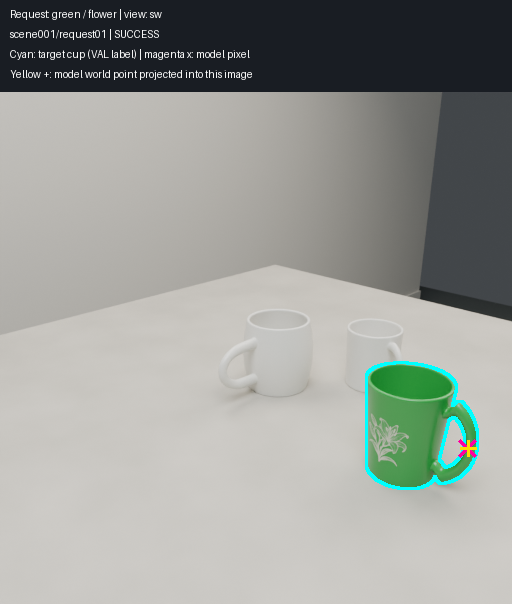

Cyan outline: target cup. The robot view does not display the original cup patterns.


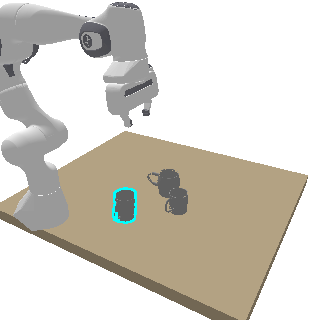

In [64]:
from common.visualization import visualize_picking

RUN_DEMO = True
if RUN_DEMO and predictor is not None:
    demo_output = RUN_DIR / "demos" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    demo = visualize_picking(
        predictor, sample["sample_id"], max_level=MAX_LEVEL, data_root=DATA_DIR,
        model_name=MODEL_NAME, views=VIEWS, output=demo_output,
    )


## 9. Prediction Evaluation

The shared evaluator reports the same per-level prediction table as the baseline, including point-on-target rate, reference-pair count, mean reference error in pixels, NO_PICKs, and model errors. It saves predictions and diagnostics for the selected validation requests. Picking success is measured separately in section 10.

In [65]:
from IPython.display import display
from common.validation import evaluate_predictions

PREDICTION_DIR = None
if predictor is not None:
    PREDICTION_DIR, prediction_table = evaluate_predictions(
        predictor, max_level=MAX_LEVEL, data_root=DATA_DIR,
        views=VIEWS, model_name=MODEL_NAME, output_root=RUN_DIR, checkpoint=CHECKPOINT_PATH,
    )
    display(prediction_table)
    print("Saved predictions:", PREDICTION_DIR)

improved prediction: 100%|██████████| 546/546 [02:08<00:00,  4.24request/s]


,level,requests,point_on_target,point_on_target_rate,reference_pairs,mean_reference_error_px,no_pick,model_errors
0,L1,280,217,0.775000,256,59.406681,0,0
1,L2,216,138,0.638889,209,79.756596,0,0
2,L3,50,22,0.440000,0,NaN,0,0


Saved predictions: C:\Users\lucas\Downloads\cafe_project-20261118T022300Z-1-001\cafe_project\runs\improved_20261127_152942_094275\predictions_20261127_152953_824236


## 10. Picking Evaluation

The shared simulator reuses the saved predictions to score actual cup lifts. Set `RUN_PICKING=True` to run this slower step.

In [66]:
from common.validation import evaluate_saved_picking

RUN_PICKING = True
if RUN_PICKING and PREDICTION_DIR is not None:
    picking_table = evaluate_saved_picking(PREDICTION_DIR, data_root=DATA_DIR, robot_workers=2)
    display(picking_table)

improved robot (2 workers): 100%|██████████| 546/546 [07:57<00:00,  1.14request/s]


Robot evaluation elapsed time: 8.0 minutes
Saved picking results: C:\Users\lucas\Downloads\cafe_project-20261118T022300Z-1-001\cafe_project\runs\improved_20261127_152942_094275\predictions_20261127_152953_824236\picking_20261127_153202_831871


,level,requests,successes,success_rate,model_errors,other_cup_lifted,pick_failed,no_pick
0,L1,280,179,0.639286,0,58,43,0
1,L2,216,105,0.486111,0,58,53,0
2,L3,50,17,0.340000,0,22,11,0
